# 2. Individual signal results

## 2.1 Why use these signals?

DMD estimates a model of how recent prices move over time. It uses that model to forecast the direction of each stock over the holding period. Repeated price patterns can give the model useful information. Momentum and reversal also use past prices, so we measure how much they overlap with DMD.

Investors can pay more for stocks that hedge bad inflation shocks. Higher prices can lower expected returns. We test a strategy that favors stocks with low inflation beta. The inflation risk premium can change sign as the link between inflation and future consumption changes. [New York Fed Staff Report 621](https://www.newyorkfed.org/research/staff_reports/sr621.html)

In [1]:
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

DATA = Path('dataset')
returns = pd.read_parquet(DATA / 'regular_dmd_returns.parquet')
returns['date'] = pd.to_datetime(returns['date'])
returns['return_date'] = pd.to_datetime(returns['return_date'])
returns = returns.sort_values('return_date')
SIGNALS = ['dmd', 'adjusted', 'inflation_beta']
BLENDS = ['bma_original', 'bma_adjusted']
VARIANTS = {'long_short': 'Long-short', 'long_only': 'Long-only'}
LABELS = {
    'dmd': 'Original DMD',
    'adjusted': 'DMD adjusted for momentum and reversal',
    'inflation_beta': 'Betting Against Inflation Beta',
    'bma_original': 'Bayesian blend with original DMD',
    'bma_adjusted': 'Bayesian blend with adjusted DMD',
}
COLORS = dict(zip(LABELS, ['#2264a7', '#df781e', '#259145', '#2264a7', '#df781e']))

def growth(group, relative):
    # Use log returns to build a compound return path.
    log_return = np.log1p(group['portfolio_return'].to_numpy())
    if relative:
        log_return -= np.log1p(group['benchmark_return'].to_numpy())
    return np.r_[0.0, log_return.cumsum()]

def max_drawdown(path):
    # Start at wealth of one, before the first holding return.
    return np.expm1(path - np.maximum.accumulate(path)).min()

def chart(models, title, relative):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, (variant, label) in zip(axes, VARIANTS.items()):
        for model in models:
            group = returns.loc[(returns['portfolio'] == model) & (returns['variant'] == variant)]
            ax.plot(group['return_date'], np.expm1(growth(group, relative)[1:]),
                    label=LABELS[model], color=COLORS[model])
        if not relative:
            benchmark = np.expm1(np.log1p(group['benchmark_return']).cumsum())
            ax.plot(group['return_date'], benchmark, '--', color='0.35', label='Benchmark')
        ax.set_title(label)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis='y', alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('Cumulative benchmark-relative return' if relative else 'Cumulative total return')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=min(len(labels), 2), frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, .12, 1, .92))
    plt.show()


## 2.2 Show standalone returns

The active charts show portfolio wealth divided by benchmark wealth, less one. The total charts show compound total return and include the benchmark. Returns are before trading costs.

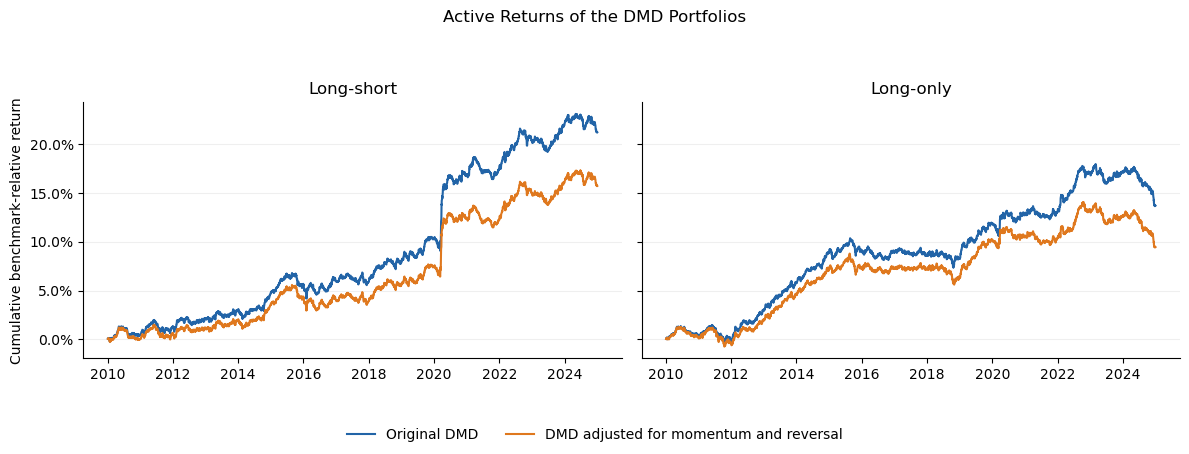

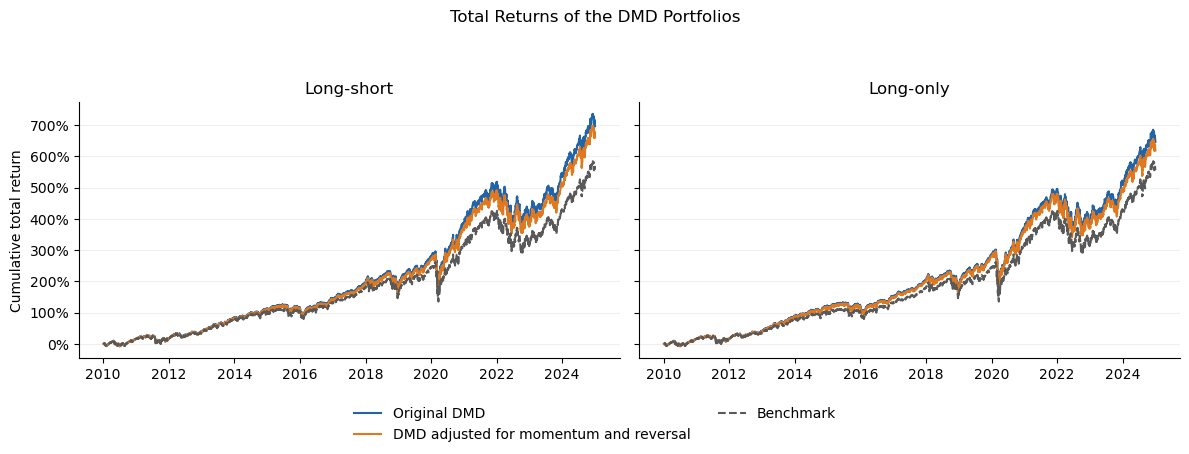

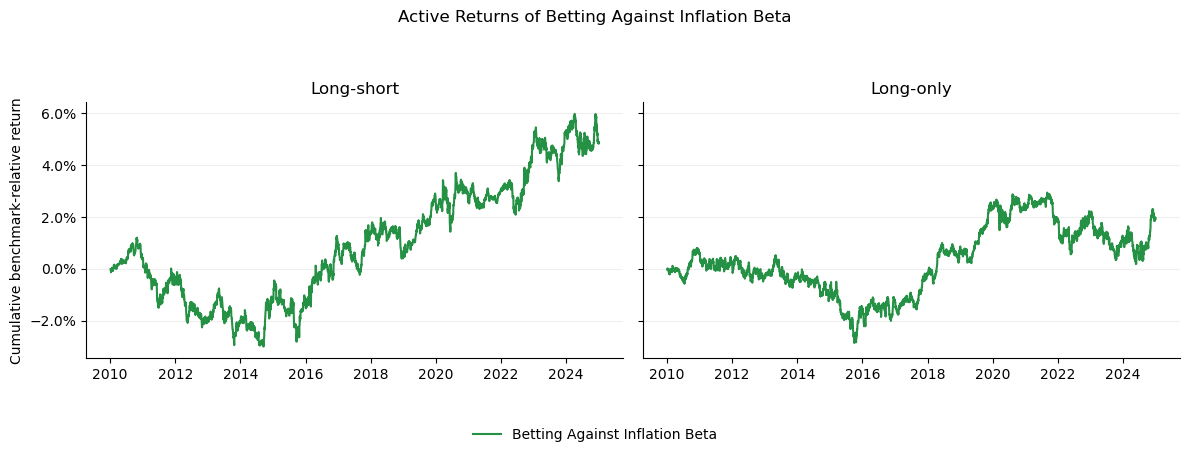

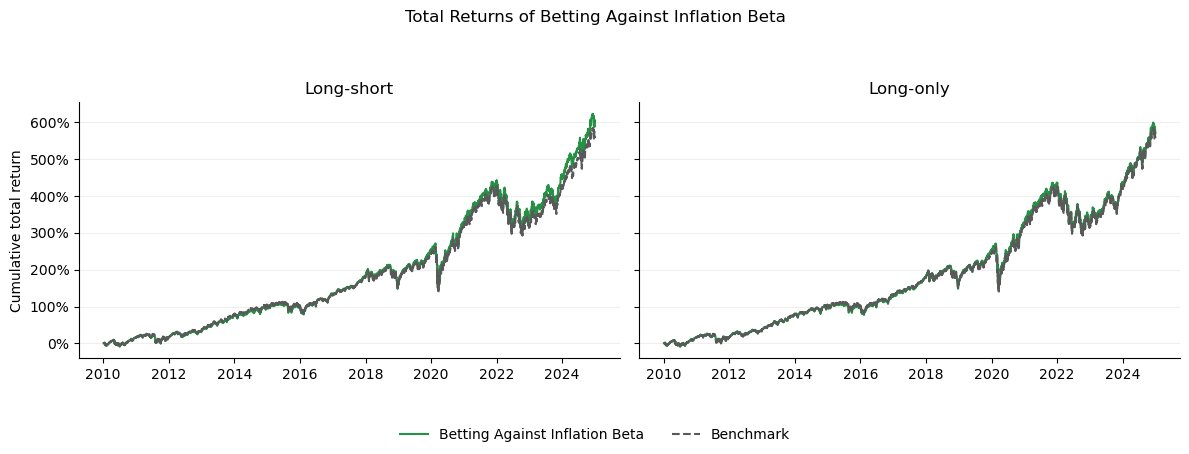

In [2]:
chart(['dmd', 'adjusted'], 'Active Returns of the DMD Portfolios', True)
chart(['dmd', 'adjusted'], 'Total Returns of the DMD Portfolios', False)
chart(['inflation_beta'], 'Active Returns of Betting Against Inflation Beta', True)
chart(['inflation_beta'], 'Total Returns of Betting Against Inflation Beta', False)

## 2.3 Measure DMD score and payoff overlap

The stock-level attribution test projects DMD onto each set of control scores. The score variation column measures how much of the original DMD score the controls explain. The payoff column measures the share of DMD stock-level payoff associated with that fitted part. A small share of score variation can have a large share of payoff if the fitted scores align with subsequent returns.

The adjusted portfolio charts above use the sf-quant pair. The Barra pair is a separate attribution test. Portfolio returns also depend on the optimizer and its constraints.

In [3]:
daily = pd.read_parquet(DATA / 'dmd_style_attribution_daily.parquet')
attribution = daily.groupby('controls').agg(
    sessions=('score_r2', 'size'), score_share=('score_r2', 'mean'),
    original_payoff=('raw_payoff', 'mean'), fitted_payoff=('explained_payoff', 'mean'))
attribution['payoff_share'] = attribution['fitted_payoff'] / attribution['original_payoff']
attribution = attribution.loc[['sf_quant', 'barra', 'all'], ['sessions', 'score_share', 'payoff_share']]
attribution.index = ['sf-quant momentum and reversal', 'Barra momentum and long-term reversal', 'All four controls']
attribution.columns = ['Sessions', 'DMD score variation explained', 'DMD payoff associated with fitted scores']
display(attribution.style.format({attribution.columns[1]: '{:.2%}', attribution.columns[2]: '{:.1%}'}))

coverage = pd.read_parquet(DATA / 'regular_dmd_coverage.parquet')
coverage['date'] = pd.to_datetime(coverage['date'])
test_dates = returns['date'].drop_duplicates()
test_coverage = coverage.loc[coverage['date'].isin(test_dates), 'matched_share']
assert len(test_coverage) == 3773
print(f'Mean daily share with DMD and both sf-quant scores: {test_coverage.mean():.2%}')

,Sessions,DMD score variation explained,DMD payoff associated with fitted scores
sf-quant momentum and reversal,3773,1.39%,39.3%
Barra momentum and long-term reversal,3773,0.30%,17.1%
All four controls,3773,1.54%,45.5%


Mean daily share with DMD and both sf-quant scores: 95.79%


## 2.4 Compare standalone risk and return

In [4]:
rows = []
for model in SIGNALS:
    for variant, label in VARIANTS.items():
        group = returns.loc[(returns['portfolio'] == model) & (returns['variant'] == variant)]
        active = group['active_return']
        active_return = 252 * active.mean()
        tracking_error = np.sqrt(252) * active.std(ddof=1)
        rows.append({
            'Portfolio': LABELS[model], 'Constraint': label,
            'Annualized active return': active_return,
            'Information ratio': active_return / tracking_error,
            'Realized tracking error': tracking_error,
            'Total return CAGR': np.expm1(growth(group, False)[-1] * 252 / len(group)),
        })
table = pd.DataFrame(rows).set_index(['Portfolio', 'Constraint'])
display(table.style.format({c: '{:.2f}' if c == 'Information ratio' else '{:.2%}' for c in table}))

After the sf-quant adjustment, DMD still earned 1.00% long-short and 0.62% long-only in annualized active return before costs. Original DMD earned 1.32% and 0.89%, respectively. The portfolio comparison includes the effect of changes in scores and in which stocks have an adjusted score.